# Customer value, spending trajectories and retention

Reference: **Two_Analytics_Projects_Complete_Guide.docx, Steps 1.3.1–1.3.5**. SQL: `sql/03_customers.sql`; reproducible runner: `scripts/run_customers.py`.

This notebook reads verified exports without taking a DBeaver database lock.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'exports/customers/hh_segments.csv').exists():
    ROOT = ROOT / 'outputs/grocery-marketing-effectiveness'
DATA = ROOT / 'exports/customers'
households = pd.read_csv(DATA / 'hh_segments.csv', dtype={'household_id': str})
segments = pd.read_csv(DATA / 'customer_segment_summary.csv')
trajectories = pd.read_csv(DATA / 'customer_trajectory_summary.csv')
cohorts = pd.read_csv(DATA / 'cohort_retention.csv', parse_dates=['cohort'])
income = pd.read_csv(DATA / 'income_spend.csv')
coverage = pd.read_csv(DATA / 'demographic_coverage_spend.csv')
checks = pd.read_csv(DATA / 'customer_checks.csv')
assert len(households) == 2467 and households.household_id.is_unique
assert checks.passed.astype(str).str.lower().eq('true').all()
assert abs(segments.value_share.sum() - 1) < 1e-6
print(f'{len(households):,} grocery households; {len(checks)} database checks passed')

2,467 grocery households; 18 database checks passed


## 1. Household metrics and segments

Snapshot: 31 December 2017. Lapsed status takes precedence. The guide uses grocery spend; two non-grocery-only households are outside this model. UNKNOWN-product purchases remain within the not-explicitly-non-grocery filter.

,spend_p75,spend_p50,baskets_p75,discount_p75
0,2332.505,1152.73,75.0,0.193


,segment,households,spend,value_share,avg_baskets
0,1 Champions,416,1870445.11,0.446934,144.812500
1,2 Loyal regulars,804,1683639.31,0.402298,62.046020
2,3 Light regulars,800,504643.04,0.120582,32.817500
3,4 Occasional,225,48106.18,0.011495,6.991111
4,5 Lapsed,222,78222.00,0.018691,14.004505


,households,top_20pct_households,top_20pct_spend,top_20pct_value_share
0,2467,494,2243258.11,0.536016


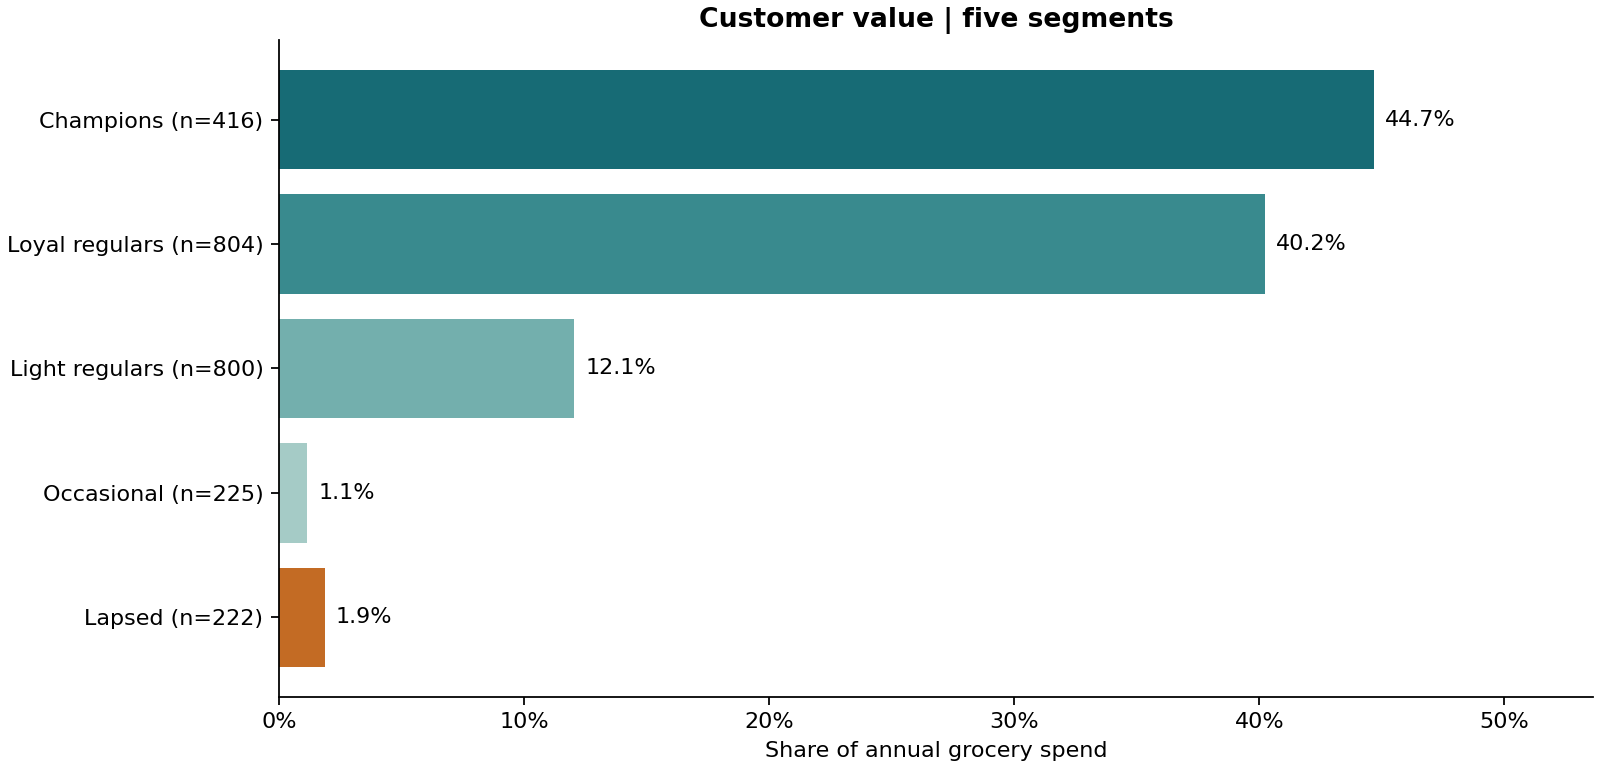

In [2]:
display(households.head())
display(pd.read_csv(DATA / 'customer_cutoffs.csv'))
display(segments)
display(pd.read_csv(DATA / 'spend_concentration.csv'))
display(Image(filename=str(ROOT / 'charts/customer_segments.png')))

## 2. Spend trajectories

H1: source weeks 2–27; H2: 28–53. Growing means at least +20%; Declining means at least -20%. Partial week 1 is excluded from the comparison. New/Gone labels describe observed spending, not proven acquisition/churn. The observed decline is not a recoverable-revenue estimate.

,trajectory,households,household_share,spend_h1,spend_h2,spend_change
0,Growing,866,0.351034,476545.46,818773.30,342227.84
1,Declining,755,0.306040,699334.10,379860.61,-319473.49
2,Stable,709,0.287394,892462.14,882928.88,-9533.26
3,New in H2,78,0.031617,0.00,18835.28,18835.28
4,Gone in H2,59,0.023916,6209.02,0.00,-6209.02


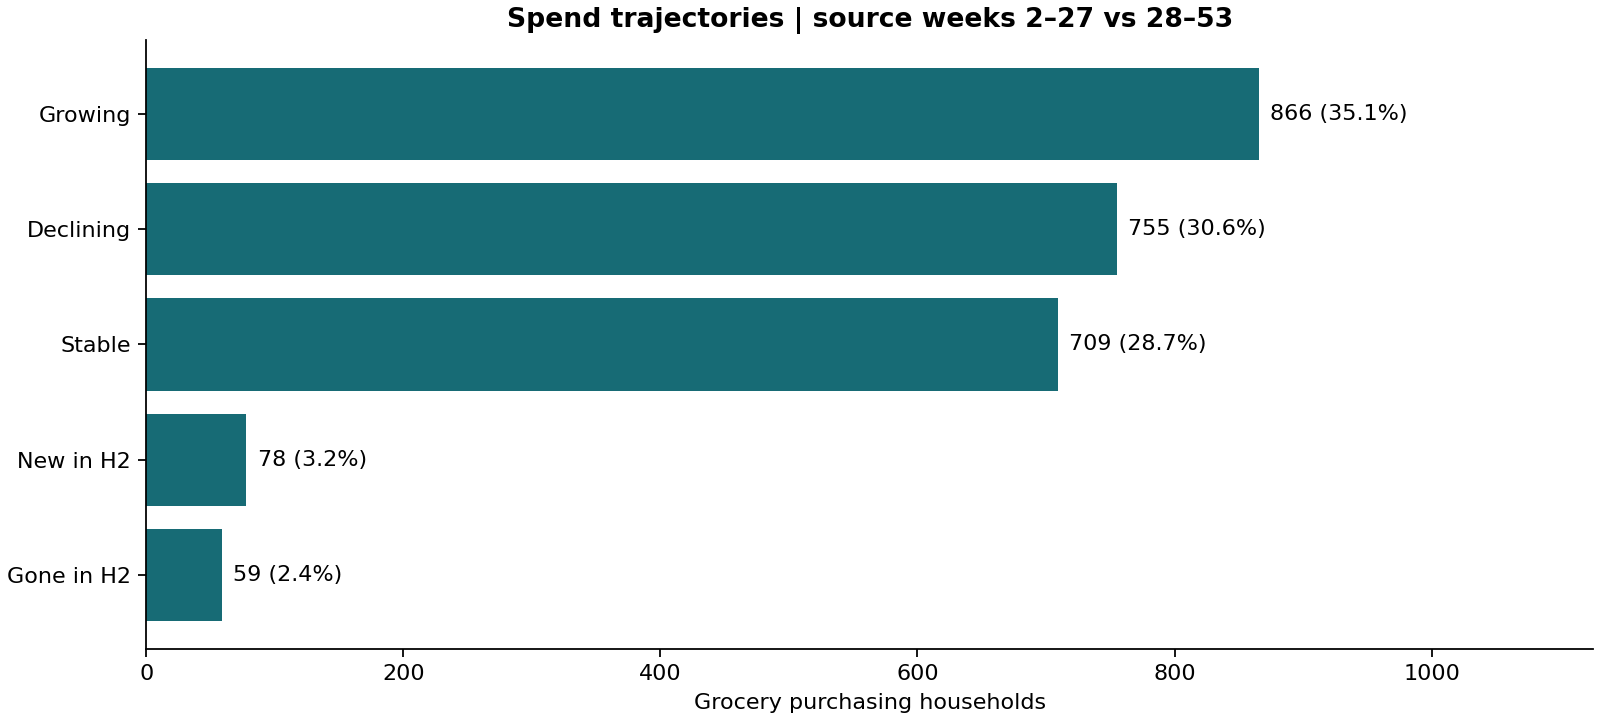

In [3]:
display(trajectories)
display(Image(filename=str(ROOT / 'charts/customer_trajectories.png')))

## 3. Monthly retention cohorts

Following the guide, this section uses all clean purchases (2,469 households), not the grocery-only segment population. First observed purchase is not proven acquisition. Elapsed inactive months are zero; unobservable future months are blank. Activity can resume after a missed month.

,cohort,cohort_size
0,2017-01-01,1983
12,2017-02-01,185
23,2017-03-01,112
33,2017-04-01,47
42,2017-05-01,46
50,2017-06-01,20
57,2017-07-01,21
63,2017-08-01,16
68,2017-09-01,16
72,2017-10-01,6


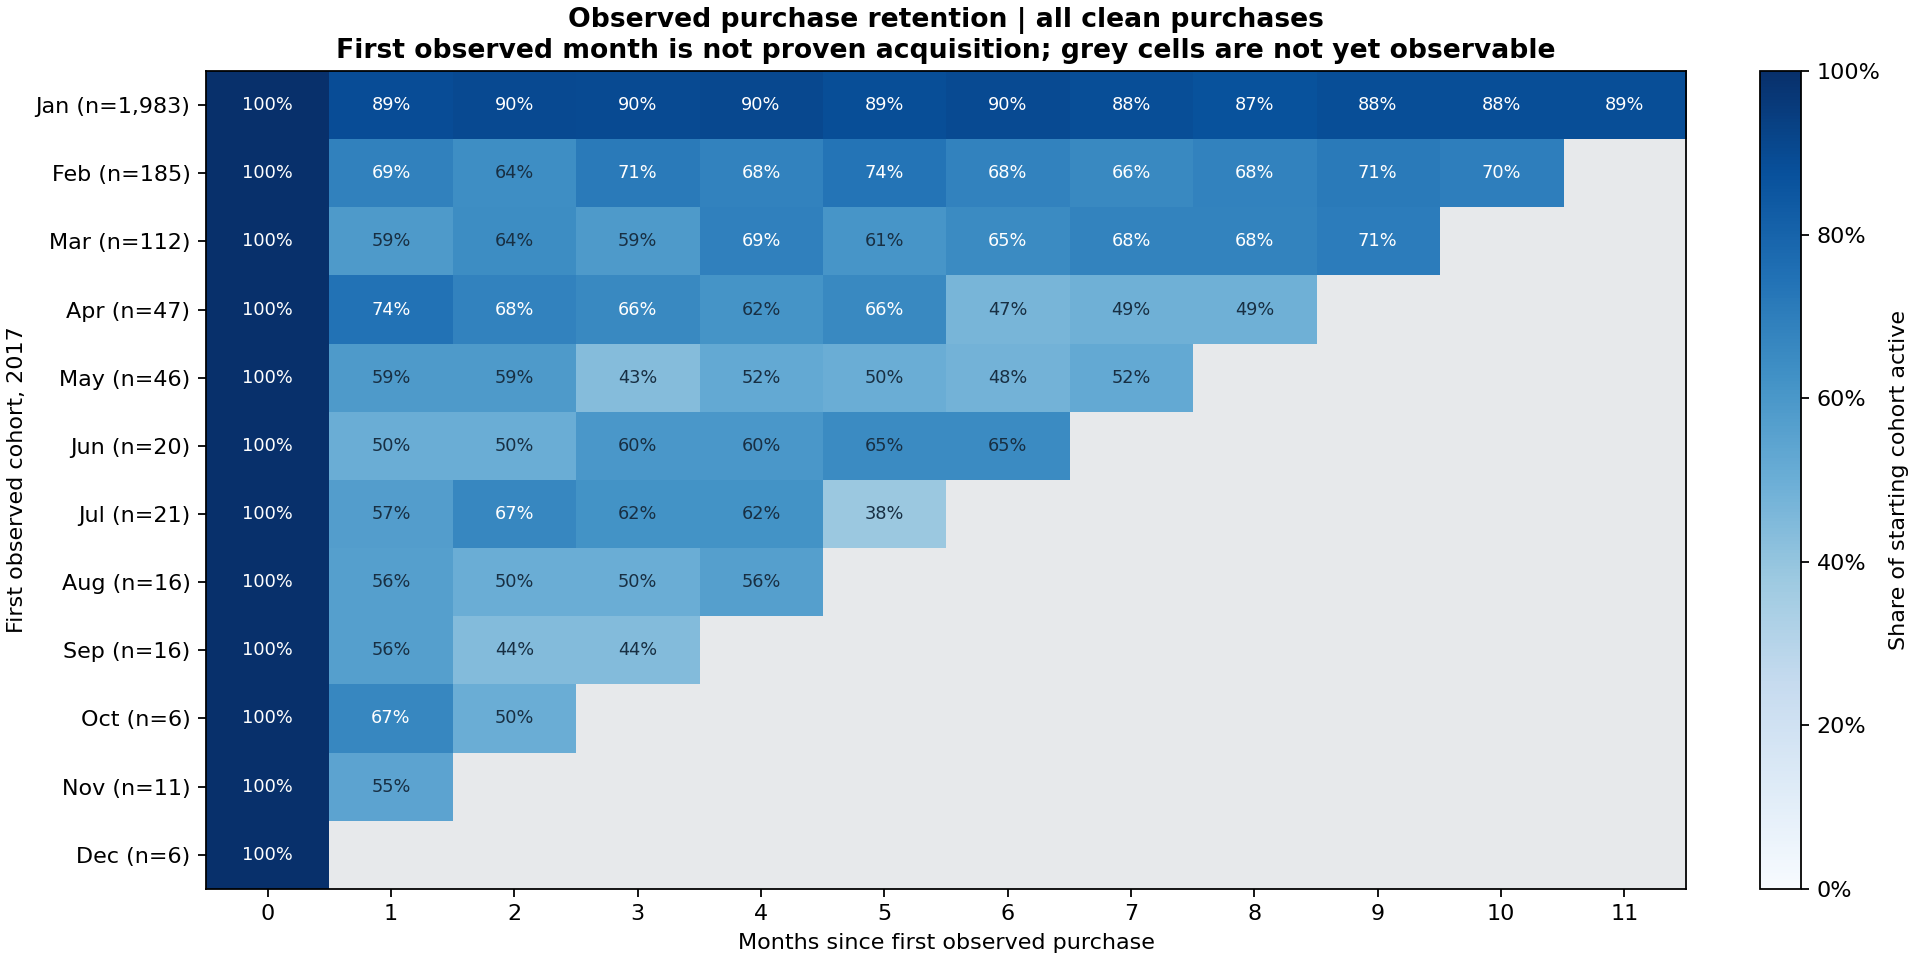

In [4]:
display(cohorts[cohorts.months_since_first == 0][['cohort', 'cohort_size']])
assert cohorts.loc[cohorts.months_since_first == 0, 'cohort_size'].sum() == 2469
assert cohorts.retention.between(0, 1).all()
display(Image(filename=str(ROOT / 'charts/cohort_retention.png')))

## 4. Demographic attributes and spend

These are descriptive associations. The demographic subset spends more and does not represent the whole panel; small income bands are explicitly flagged. Missing attributes are not imputed.

,has_demographics,households,median_spend,mean_spend
0,False,1666,682.535,1091.599748
1,True,801,2407.660,2954.370112


,income,households,median_spend,mean_spend,small_group
0,15-24K,74,1972.425,2226.578784,False
1,35-49K,172,2141.915,2566.595000,False
2,25-34K,77,2183.410,2630.165974,False
3,Under 15K,61,2190.000,2850.248197,False
4,75-99K,96,2505.335,3137.008750,False
5,50-74K,192,2547.275,2986.547135,False
6,200-249K,5,2722.830,3019.296000,True
7,100-124K,34,2838.215,2936.111765,False
8,125-149K,38,2885.195,3967.037632,False
9,175-199K,11,4054.690,4151.954545,True


,deal_driven,households,mean_spend,median_spend
0,False,1843,1801.949246,1227.64
1,True,624,1384.716635,933.22


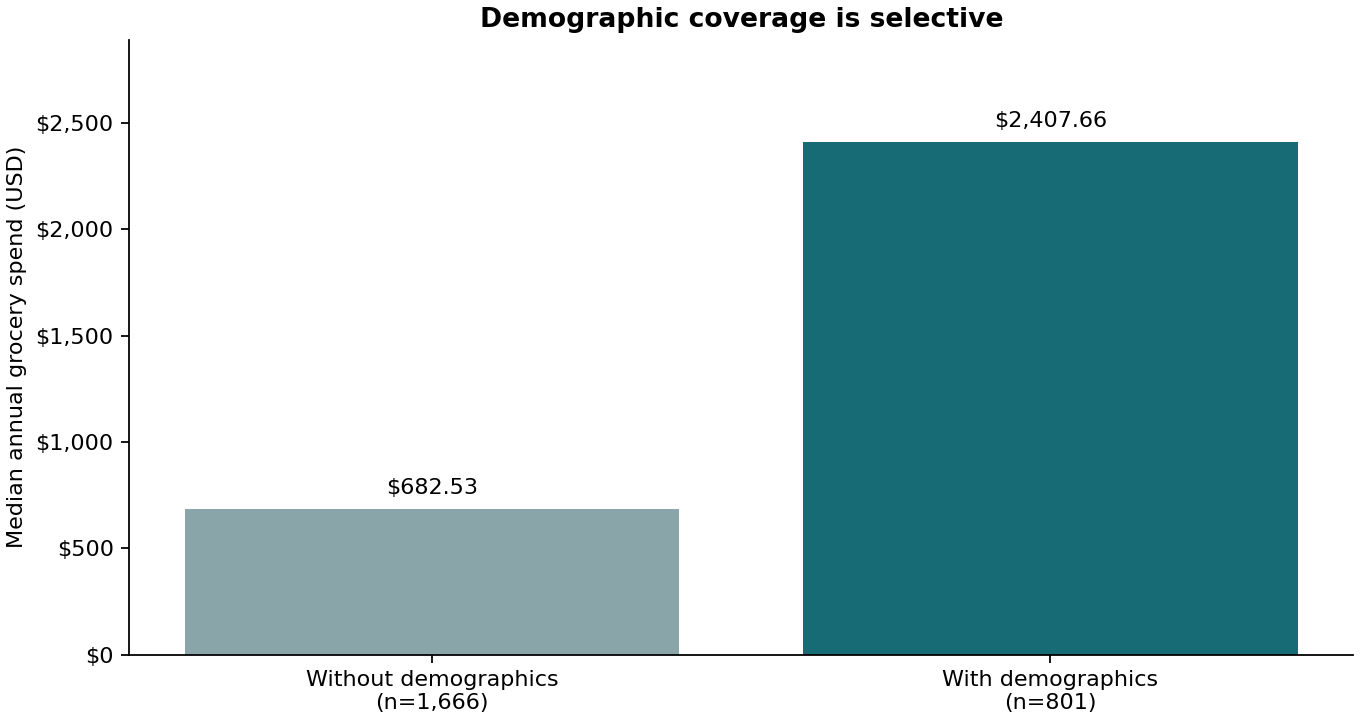

In [5]:
display(coverage)
display(income)
display(pd.read_csv(DATA / 'deal_driven_spend.csv'))
display(Image(filename=str(ROOT / 'charts/demographic_selection.png')))

## 5. Findings and validation

In [6]:
display(checks)
display(Markdown((ROOT / 'docs/customers/findings.md').read_text(encoding='utf-8')))

,check_name,passed
0,household_keys_unique,True
1,grocery_households_reconcile,True
2,grocery_spend_reconciles,True
3,segment_counts_reconcile,True
4,segment_value_shares_sum_to_one,True
5,trajectory_counts_reconcile,True
6,half_year_spend_reconciles,True
7,lapsed_precedence,True
8,recency_not_negative,True
9,cohort_keys_unique,True


# Customer value and retention

Completed Steps **1.3.1–1.3.5**. These segments describe observed behaviour; they are not validated predictions of future value or proof of marketing effects.

## Three findings

1. **416 Champions generate 44.7% of grocery spend.** The top 20% by spend (rounded up to 494 households) account for **53.6%**. This identifies a concentrated customer base for service and retention investigation; it does not establish future lifetime value.
2. **755 households have declining spend**, using a 20% decline threshold. Their spend moves from **$699,334.10** in H1 to **$379,860.61** in H2, an observed reduction of **$319,473.49**. This is not a forecast of revenue that a retention campaign can recover.
3. Households with demographics have median annual grocery spend of **$2,407.66**, versus **$682.53** without demographics. Income comparisons therefore describe a selective subset and should not be generalized to all households or treated as causal effects.

## Value segments

| Segment | Households | Annual grocery spend | Spend share |
|---|---:|---:|---:|
| Champions | 416 | $1,870,445.11 | 44.7% |
| Loyal regulars | 804 | $1,683,639.31 | 40.2% |
| Light regulars | 800 | $504,643.04 | 12.1% |
| Occasional | 225 | $48,106.18 | 1.1% |
| Lapsed | 222 | $78,222.00 | 1.9% |

## Spend trajectories

| Trajectory | Households | Household share | H1 spend | H2 spend |
|---|---:|---:|---:|---:|
| Growing | 866 | 35.1% | $476,545.46 | $818,773.30 |
| Declining | 755 | 30.6% | $699,334.10 | $379,860.61 |
| Stable | 709 | 28.7% | $892,462.14 | $882,928.88 |
| New in H2 | 78 | 3.2% | $0.00 | $18,835.28 |
| Gone in H2 | 59 | 2.4% | $6,209.02 | $0.00 |

H1 uses source weeks 2–27; H2 uses weeks 28–53. Partial week 1 is excluded from that comparison but retained in annual spend. Growing means at least +20%; Declining means at least -20%; New/Gone labels mean no recorded positive spend in the other half, not proven acquisition/churn. No-spend-in-both-halves cases have an explicit label instead of being misclassified as new.

## Retention and demographics

The cohort model uses the **all-clean-purchase** scope: 2,469 households, including two non-grocery-only households. Segments use **grocery purchases**: 2,467 households. Do not mix those denominators.

January is the first observed month for **1,983 households**. This panel starts in January; first observation does not prove those shoppers were newly acquired. Elapsed months without purchases are zero retention; future months are omitted/masked, never zero-filled. Monthly activity is nonconsecutive retention, so a household may return after a missed month.

Income-band comparisons include household counts and a small-group flag (<30). The flag is a descriptive caution, not a formal significance threshold. Missing attributes are not imputed. The deal-driven flag uses a rounded discount-share upper quartile; ties mean it need not identify exactly 25% of households.

## Verification and files

**18 full-data checks passed**, plus source fingerprint/model checks. The main outputs are `exports/customers/`, four chart PNGs, `03_customers.ipynb`, and `sql/03_customers.sql`. Exported retention rates retain full precision; the guide rounds them to three decimals. Segment/trajectory counts are computed from the actual data rather than forced to match the guide.

The reporting database `grocery_customers.duckdb` contains customer tables and checks, not raw purchases.


## Next guide section

Module 4: promotion lift, followed by campaign incrementality. Customer descriptions above are not causal marketing estimates.